# Baseline TF-IDF: contexto + documento citado (A/B)

Experimento preliminar sobre las particiones recibidas. **No valida los vínculos bibliográficos ni la homologación a las nueve funciones de la propuesta.** Conserva las etiquetas actuales del dataset, sin corregirlas ni generar ejemplos.

* A: contexto de cita + título + abstract del citado.
* B: contexto de cita + hasta tres chunks del citado, ordenados por rango. No incorpora título/abstract.
* TF-IDF + regresión logística balanceada; tres configuraciones por estrategia, seis corridas MLflow. Se varían conjuntamente n-gramas, min_df y C: no son repeticiones entre semillas ni una ablación causal.
* Vocabulario e IDF se ajustan solo en train. Selección por F1 macro de dev sobre las nueve etiquetas actuales; test se consulta únicamente para el ganador de cada estrategia.

Se conservan las mismas filas en A/B, incluidos los casos con menos de tres chunks, que se contabilizan. Las cuatro clases ausentes de test impiden evaluar nueve clases de forma completa. No se usa `instances_a1.jsonl`.

Ejecución desde la raíz con uv, sin cambiar pyproject ni uv.lock:
```bash
uv run --no-project --with numpy --with pandas --with scikit-learn --with matplotlib --with mlflow --with nbformat --with nbclient --with ipykernel --with nbconvert jupyter nbconvert --to notebook --execute --inplace notebooks/01_baseline_tfidf_ab.ipynb --ExecutePreprocessor.timeout=1800
```
Datos esperados: data/dataset/{train,dev,test}.jsonl. Artefactos locales: mlruns/baseline_ab/. Solo este notebook se versiona; contiene resultados agregados, no filas del dataset.

In [1]:
from pathlib import Path
import hashlib, json, re, time, warnings, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
import mlflow
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/dataset/train.jsonl').exists())
DATA = ROOT/'data/dataset'
OUT = ROOT/'mlruns/baseline_ab'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ['Background','Uses','Comparison','Extends','Motivation','Future Work','Evidence','Originator','Further Reading']
SEED = 42
VERSIONS = {p:version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','mlflow','nbclient']}
display(pd.Series(VERSIONS, name='version').to_frame())
mlflow.set_tracking_uri('sqlite:///' + (ROOT/'mlruns/baseline_ab/mlflow.db').as_posix())
mlflow.set_experiment('EvidenCite-TFIDF-AB-dataset-recibido')

,version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
mlflow,3.17.2
nbclient,0.11.0


2026/10/22 01:36:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/22 01:36:10 INFO mlflow.store.db.utils: Updating database tables


2026/10/22 01:36:12 INFO mlflow.tracking.fluent: Experiment with name 'EvidenCite-TFIDF-AB-dataset-recibido' does not exist. Creating a new experiment.


<Experiment: artifact_location='/home/jmalaver/projects/EvidenCite/notebooks/mlruns/1', creation_time=1792650972673, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792650972673, lifecycle_stage='active', name='EvidenCite-TFIDF-AB-dataset-recibido', tags={}, trace_location=None, workspace='default'>

In [2]:
splits = {s:[json.loads(line) for line in (DATA/f'{s}.jsonl').read_text().splitlines() if line.strip()] for s in ['train','dev','test']}
hashes = {s:hashlib.sha256((DATA/f'{s}.jsonl').read_bytes()).hexdigest() for s in splits}
def normalized(s): return re.sub(r'\s+', ' ', s).strip().lower()
for s, rows in splits.items():
    assert rows and len({r['instance_id'] for r in rows}) == len(rows)
    assert all(r['label'] in LABELS for r in rows)
    assert all(r['citation_context'].strip() and r['cited_paper']['title'] and r['cited_paper']['abstract'] and r['cited_paper']['retrieved_chunks'] for r in rows)
for a,b in [('train','dev'),('train','test'),('dev','test')]:
    for getter in [lambda r:r['instance_id'], lambda r:r['citing_paper']['id'], lambda r:normalized(r['citation_context'])]:
        assert not ({getter(r) for r in splits[a]} & {getter(r) for r in splits[b]}), f'Solapamiento {a}/{b}'
counts = pd.DataFrame({s:pd.Series([r['label'] for r in rows]).value_counts() for s,rows in splits.items()}).reindex(LABELS).fillna(0).astype(int)
summary = pd.DataFrame({s:{'ejemplos':len(rows),'citantes':len({r['citing_paper']['id'] for r in rows}),'pares':len({(r['citing_paper']['id'],r['cited_paper']['id']) for r in rows}),'menos_de_3_chunks':sum(len(r['cited_paper']['retrieved_chunks'])<3 for r in rows),'gold_declarado_origen':sum(r['annotation_metadata']['is_gold'] for r in rows)} for s,rows in splits.items()}).T
display(summary); display(counts)
print('Clases sin soporte en test:', counts.index[counts['test']==0].tolist())
manifest = {'sha256':hashes,'versions':VERSIONS,'python':platform.python_version(),'labels':LABELS,'splits':summary.to_dict(orient='index'),'class_counts':counts.to_dict(),'limitations':['Identidad del citado no revalidada','Taxonomía actual distinta de proposal-v1','Gold de origen no acredita homologación','Test sin soporte en cuatro clases','Chunks precomputados: recuperador no evaluado aquí']}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')

,ejemplos,citantes,pares,menos_de_3_chunks,gold_declarado_origen
train,2255,615,646,8,1776
dev,491,26,28,0,473
test,486,16,17,24,486


,train,dev,test
Background,612,113,149
Uses,556,172,167
Comparison,422,129,121
Extends,149,29,20
Motivation,85,28,29
Future Work,8,2,0
Evidence,156,0,0
Originator,26,0,0
Further Reading,241,18,0


Clases sin soporte en test: ['Future Work', 'Evidence', 'Originator', 'Further Reading']


2097

## Representaciones y protocolo
Se eliminan únicamente las etiquetas HTML `<cite>`; se conserva su contenido textual y el contexto completo. Se concatenan campos con saltos de línea y se aplica un único TF-IDF por estrategia, sin pesos de campo ni truncamiento por tokens. B usa los chunks ya recibidos: no vuelve a ejecutar recuperación ni certifica su pertinencia.

F1 macro-9 incluye siempre las nueve etiquetas actuales, con cero para clases no evaluables; se acompaña con F1 macro sobre clases con soporte para evitar confundir ausencia con desempeño. La selección usa macro-9 de dev. Los pesos balanceados se calculan en train. No se reentrena con dev antes de evaluar test.

In [3]:
def input_text(row, strategy):
    context = re.sub(r'</?cite>', '', row['citation_context'])
    cited = row['cited_paper']
    evidence = [cited['title'], cited['abstract']] if strategy=='A' else [c['text'] for c in sorted(cited['retrieved_chunks'],key=lambda c:c.get('rank',999))[:3]]
    return '\n'.join([context,*evidence])
X = {strategy:{s:[input_text(r,strategy) for r in rows] for s,rows in splits.items()} for strategy in ['A','B']}
y = {s:np.array([r['label'] for r in rows]) for s,rows in splits.items()}
CONFIGS = [{'config':'r1','ngram_max':1,'min_df':1,'C':0.5},{'config':'r2','ngram_max':2,'min_df':2,'C':1.0},{'config':'r3','ngram_max':2,'min_df':3,'C':2.0}]
def metrics(truth,pred):
    return {'accuracy':accuracy_score(truth,pred),'f1_macro_9':f1_score(truth,pred,labels=LABELS,average='macro',zero_division=0),'f1_macro_present':f1_score(truth,pred,labels=sorted(set(truth)),average='macro',zero_division=0),'f1_weighted':f1_score(truth,pred,average='weighted',zero_division=0)}
display(pd.DataFrame(CONFIGS))

,config,ngram_max,min_df,C
0,r1,1,1,0.5
1,r2,2,2,1.0
2,r3,2,3,2.0


In [4]:
runs=[]; models={}
for strategy in ['A','B']:
    for config in CONFIGS:
        model = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,config['ngram_max']),min_df=config['min_df'],max_features=100000,sublinear_tf=True)),('classifier',LogisticRegression(C=config['C'],class_weight='balanced',solver='lbfgs',max_iter=2000,random_state=SEED))])
        with mlflow.start_run(run_name=f"{strategy}_{config['config']}") as run:
            mlflow.log_params({**config,'strategy':strategy,'seed':SEED,'max_features':100000,'sublinear_tf':True,'class_weight':'balanced','solver':'lbfgs','max_iter':2000,'selection_metric':'dev_f1_macro_9'})
            mlflow.set_tags({'status_dataset':'preliminar_sin_revalidar','taxonomy':'dataset_recibido','input_A':'contexto+título+abstract','input_B':'contexto+chunks_precomputados'})
            mlflow.log_dict(manifest,'manifest.json')
            start=time.perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always'); model.fit(X[strategy]['train'],y['train'])
            elapsed=time.perf_counter()-start
            scores=metrics(y['dev'],model.predict(X[strategy]['dev']))
            values={f'dev_{k}':v for k,v in scores.items()}
            values.update(fit_seconds=elapsed,vocabulary_size=len(model['tfidf'].vocabulary_),warning_count=len(caught))
            mlflow.log_metrics(values)
            mlflow.log_dict({'warnings':[str(w.message) for w in caught]},'warnings.json')
            model_path=OUT/f"{strategy}_{config['config']}.joblib"
            joblib.dump(model,model_path); mlflow.log_artifact(str(model_path),'model')
            runs.append({'strategy':strategy,**config,**values,'run_id':run.info.run_id})
            models[(strategy,config['config'])]=model
            print(strategy,config['config'],'dev F1 macro-9 =',round(scores['f1_macro_9'],4))
results=pd.DataFrame(runs)
display(results.round(4))
results.to_csv(OUT/'dev_results.csv',index=False)

A r1 dev F1 macro-9 = 0.219


A r2 dev F1 macro-9 = 0.2503


A r3 dev F1 macro-9 = 0.2696


B r1 dev F1 macro-9 = 0.19


B r2 dev F1 macro-9 = 0.2113


B r3 dev F1 macro-9 = 0.2209


,strategy,config,ngram_max,min_df,C,dev_accuracy,dev_f1_macro_9,dev_f1_macro_present,dev_f1_weighted,fit_seconds,vocabulary_size,warning_count,run_id
0,A,r1,1,1,0.5,0.3136,0.2190,0.2816,0.3418,4.1709,14082,0,96576acc35cb40398cdd3b23f186c120
1,A,r2,2,2,1.0,0.3381,0.2503,0.3218,0.3576,9.4532,45691,0,58e963d5f34e4c0890fc58f6a86ba67f
2,A,r3,2,3,2.0,0.3849,0.2696,0.3467,0.3993,10.0354,28226,0,2be934dc7bd24c6dbf7f879746edce8c
3,B,r1,1,1,0.5,0.3279,0.1900,0.2443,0.3432,6.2120,17654,0,0d3edafad4cc4c869f37ada2079af8a3
4,B,r2,2,2,1.0,0.3544,0.2113,0.2717,0.3589,10.5125,78673,0,fdb68175a13b4b7ca972c1d210a87805
5,B,r3,2,3,2.0,0.3727,0.2209,0.2841,0.3756,12.4105,54641,0,9217acb470014bd2a85e9f4a3922f2d4


In [5]:
winners=results.sort_values(['dev_f1_macro_9','config'],ascending=[False,True]).groupby('strategy',sort=True).head(1).sort_values('strategy')
test_rows=[]; reports={}; predictions={}
for _,winner in winners.iterrows():
    strategy=winner['strategy']; model=models[(strategy,winner['config'])]
    pred=model.predict(X[strategy]['test']); predictions[strategy]=pred
    scores=metrics(y['test'],pred)
    report=classification_report(y['test'],pred,labels=LABELS,output_dict=True,zero_division=0)
    reports[strategy]=pd.DataFrame(report).T.loc[LABELS]
    test_rows.append({'strategy':strategy,'config':winner['config'],**scores,'run_id':winner['run_id']})
    with mlflow.start_run(run_id=winner['run_id']):
        mlflow.set_tag('selected_by_dev',True)
        mlflow.log_metrics({f'test_{k}':v for k,v in scores.items()})
        mlflow.log_dict(report,'test_classification_report.json')
        pd.DataFrame({'instance_id':[r['instance_id'] for r in splits['test']],'truth':y['test'],'prediction':pred}).to_csv(OUT/f'predictions_{strategy}.csv',index=False)
        mlflow.log_artifact(str(OUT/f'predictions_{strategy}.csv'))
test_results=pd.DataFrame(test_rows)
dummy=DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y['train']),1)),y['train'])
dummy_scores=metrics(y['test'],dummy.predict(np.zeros((len(y['test']),1))))
display(test_results.round(4))
print('Referencia mayoritaria entrenada solo en train:',dummy_scores)
for strategy in ['A','B']:
    print('Métricas por clase:',strategy); display(reports[strategy].round(4))
test_results.to_csv(OUT/'test_results.csv',index=False)
(OUT/'results.json').write_text(json.dumps({'dev':runs,'test':test_rows,'majority':dummy_scores,'manifest':manifest},indent=2),encoding='utf-8')

,strategy,config,accuracy,f1_macro_9,f1_macro_present,f1_weighted,run_id
0,A,r3,0.3745,0.1663,0.2993,0.4049,2be934dc7bd24c6dbf7f879746edce8c
1,B,r3,0.3045,0.1286,0.2315,0.3413,9217acb470014bd2a85e9f4a3922f2d4


Referencia mayoritaria entrenada solo en train: {'accuracy': 0.3065843621399177, 'f1_macro_9': 0.05214348206474191, 'f1_macro_present': 0.09385826771653544, 'f1_weighted': 0.14387738569715824}
Métricas por clase: A


,precision,recall,f1-score,support
Background,0.4746,0.3758,0.4195,149.0
Uses,0.5000,0.5210,0.5103,167.0
Comparison,0.5410,0.2727,0.3626,121.0
Extends,0.0536,0.1500,0.0789,20.0
Motivation,0.1579,0.1034,0.1250,29.0
Future Work,0.0000,0.0000,0.0000,0.0
Evidence,0.0000,0.0000,0.0000,0.0
Originator,0.0000,0.0000,0.0000,0.0
Further Reading,0.0000,0.0000,0.0000,0.0


Métricas por clase: B


,precision,recall,f1-score,support
Background,0.4250,0.4564,0.4401,149.0
Uses,0.4904,0.3054,0.3764,167.0
Comparison,0.4242,0.2314,0.2995,121.0
Extends,0.0000,0.0000,0.0000,20.0
Motivation,0.0526,0.0345,0.0417,29.0
Future Work,0.0000,0.0000,0.0000,0.0
Evidence,0.0000,0.0000,0.0000,0.0
Originator,0.0000,0.0000,0.0000,0.0
Further Reading,0.0000,0.0000,0.0000,0.0


5732

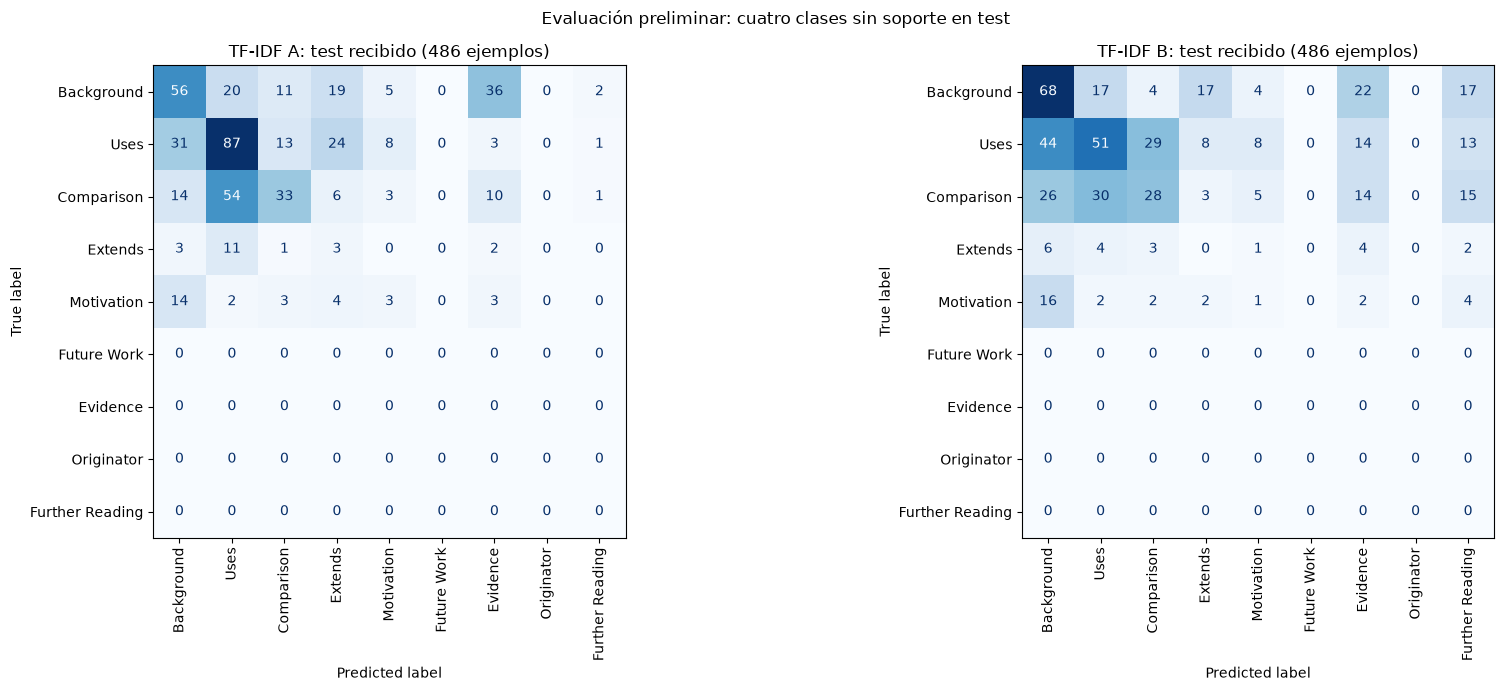

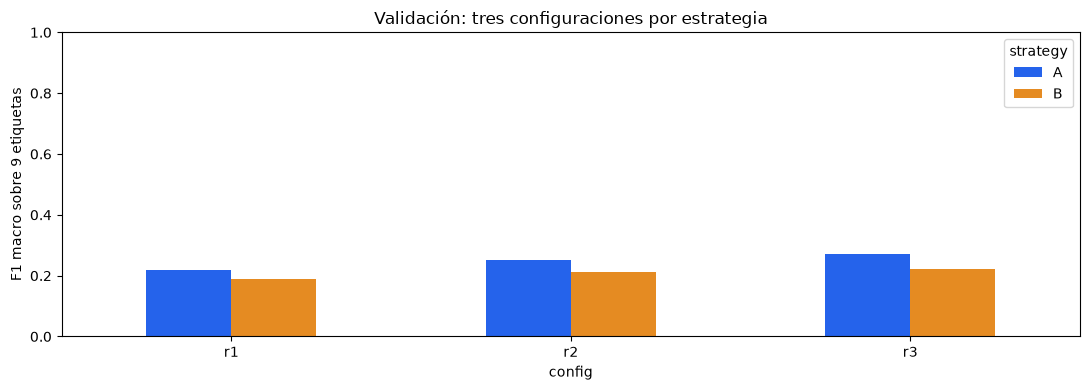

Verificación: seis corridas MLflow terminadas; dos ganadores evaluados en test.


In [6]:
fig,axes=plt.subplots(1,2,figsize=(18,7))
for ax,strategy in zip(axes,['A','B']):
    ConfusionMatrixDisplay.from_predictions(y['test'],predictions[strategy],labels=LABELS,ax=ax,cmap='Blues',colorbar=False,xticks_rotation=90)
    ax.set_title(f'TF-IDF {strategy}: test recibido (486 ejemplos)' if len(y['test'])==486 else f'TF-IDF {strategy}: test recibido')
fig.suptitle('Evaluación preliminar: cuatro clases sin soporte en test')
fig.tight_layout(); fig.savefig(OUT/'confusion_ab.png',dpi=160,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(11,4))
results.pivot(index='config',columns='strategy',values='dev_f1_macro_9').plot.bar(ax=ax,color=['#2563eb','#e58b22'])
ax.set_ylabel('F1 macro sobre 9 etiquetas'); ax.set_title('Validación: tres configuraciones por estrategia'); ax.set_ylim(0,1); ax.tick_params(axis='x',rotation=0)
fig.tight_layout(); fig.savefig(OUT/'dev_comparison.png',dpi=160); plt.show()
for row in test_rows:
    with mlflow.start_run(run_id=row['run_id']):
        mlflow.log_artifact(str(OUT/'confusion_ab.png')); mlflow.log_artifact(str(OUT/'dev_comparison.png'))
client=mlflow.tracking.MlflowClient()
assert all(client.get_run(r['run_id']).info.status=='FINISHED' for r in runs)
print('Verificación: seis corridas MLflow terminadas; dos ganadores evaluados en test.')

## Resultados e interpretación

La configuración **r3** fue seleccionada por validación en ambas estrategias.

| Estrategia | Entrada adicional al contexto | F1 macro · 9 etiquetas | F1 macro · 5 clases presentes | Exactitud |
|:--|:--|--:|--:|--:|
| **A · r3** | Título y abstract del citado | **0,1663** | **0,2993** | **0,3745** |
| **B · r3** | Chunks del citado | 0,1286 | 0,2315 | 0,3045 |
| Referencia mayoritaria | Clase más frecuente en train | 0,0521 | 0,0939 | 0,3066 |

**Lectura del resultado.** A supera a B en estas métricas sobre el test recibido. Ninguna de las seis corridas registró advertencias durante el ajuste. La comparación es descriptiva: no demuestra significancia estadística ni superioridad general.

**Alcance.** El test contiene 486 ejemplos y solo cinco de las nueve etiquetas actuales. F1 macro-9 incluye las cuatro clases sin soporte con valor cero; no significa que hayan sido evaluadas. Los vínculos bibliográficos, la pertinencia de los chunks y la homologación siguen pendientes de validación. Se conserva la selección realizada en dev.

